<a href="https://colab.research.google.com/github/raissabarb/cn/blob/main/Tarefa_Interpolacao_Erros_Raissa_e_Isabela.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.

## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

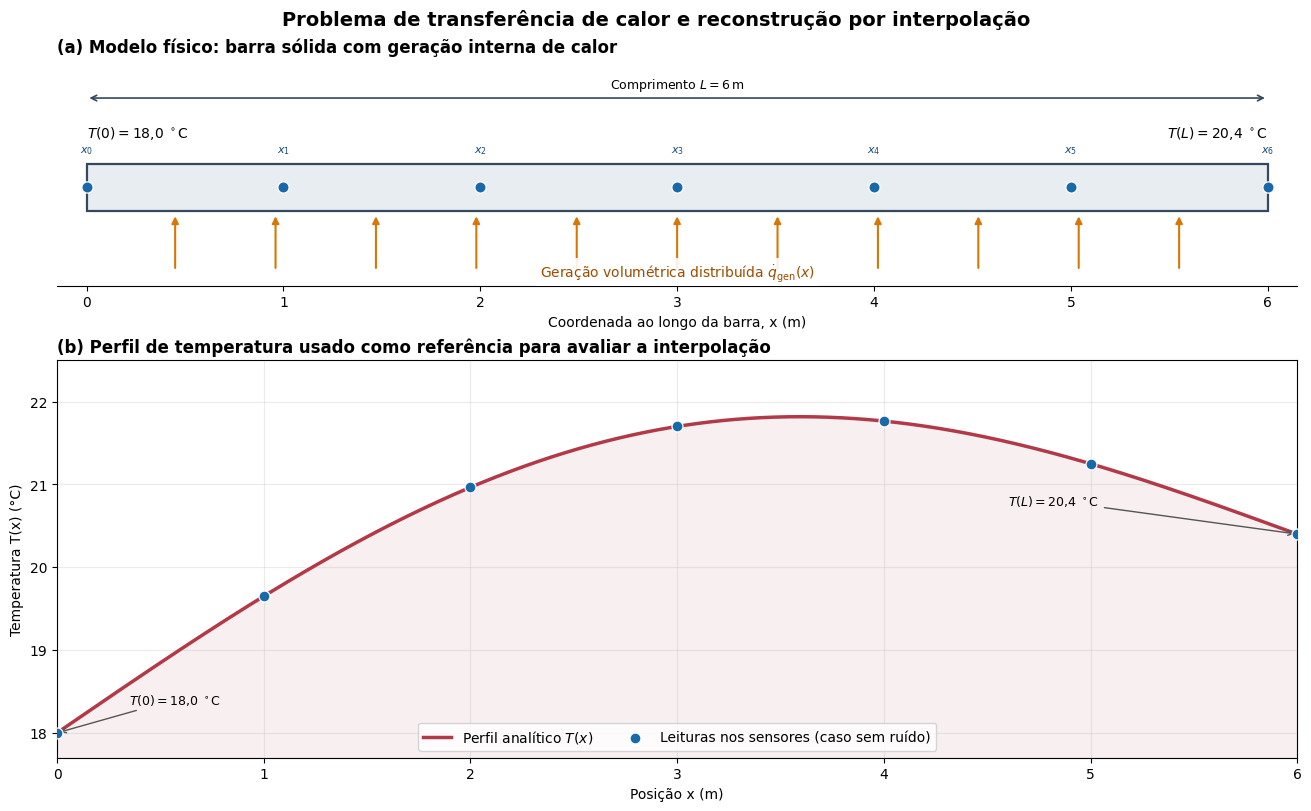

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [10]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [11]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [12]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,8.468e-05,1.918e-05,3.271e-05
1,Spline cúbica natural,5.060e-04,1.841e-04,2.391e-04
2,Spline quadrática,2.393e-02,1.495e-02,1.647e-02
3,Spline linear,8.229e-02,3.651e-02,4.397e-02


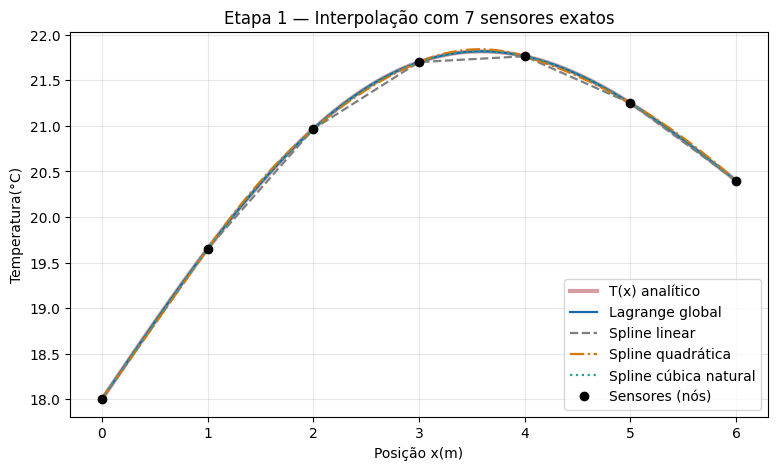

In [13]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# Métricas na malha fina (7 sensores equiespaçados)
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7.style.format({c: "{:.3e}" for c in metricas_7.columns if c != "Método"}))

# Gráfico: os quatro métodos sobrepostos à função verdadeira
cores = {"Lagrange global": "#1769aa", "Spline linear": "#7f7f7f",
         "Spline quadrática": "#d97706", "Spline cúbica natural": "#2a9d8f"}
estilos = {"Lagrange global": "-", "Spline linear": "--",
           "Spline quadrática": "-.", "Spline cúbica natural": ":"}

fig, ax = plt.subplots()
ax.plot(x_fino, T_fino, color="#b23a48", lw=3, alpha=0.5, label="T(x) analítico")

for nome, metodo in metodos_7.items():
    ax.plot(x_fino, metodo(x_fino), estilos[nome], color=cores[nome], lw=1.6, label=nome)

ax.plot(x_nos_7, y_nos_7, "ko", ms=6, label="Sensores (nós)")
ax.set_xlabel("Posição x(m)"); ax.set_ylabel("Temperatura(°C)")
ax.set_title("Etapa 1 — Interpolação com 7 sensores exatos")
ax.grid(alpha=0.3); ax.legend()
plt.show()

,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,8.468e-05,1.918e-05,3.271e-05
1,Spline cúbica natural,5.060e-04,1.841e-04,2.391e-04
2,Spline quadrática,2.393e-02,1.495e-02,1.647e-02
3,Spline linear,8.229e-02,3.651e-02,4.397e-02


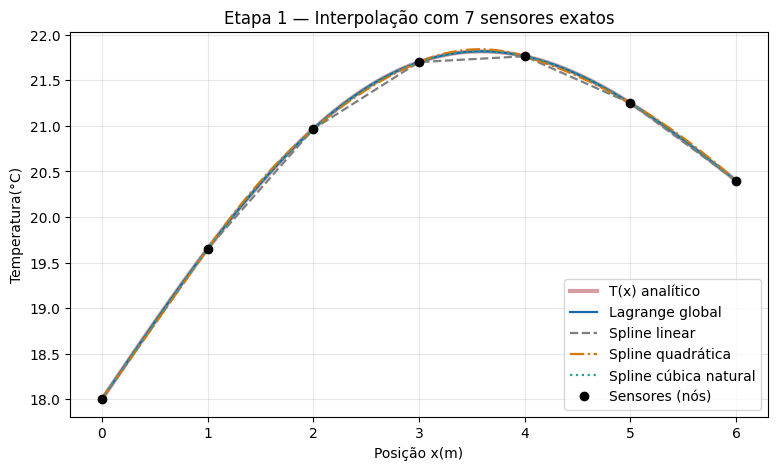

In [14]:
# Métricas na malha fina (7 sensores equiespaçados)
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7.style.format({c: "{:.3e}" for c in metricas_7.columns if c != "Método"}))

# Gráfico: os quatro métodos sobrepostos à função verdadeira
cores = {"Lagrange global": "#1769aa", "Spline linear": "#7f7f7f",
         "Spline quadrática": "#d97706", "Spline cúbica natural": "#2a9d8f"}
estilos = {"Lagrange global": "-", "Spline linear": "--",
           "Spline quadrática": "-.", "Spline cúbica natural": ":"}

fig, ax = plt.subplots()
ax.plot(x_fino, T_fino, color="#b23a48", lw=3, alpha=0.5, label="T(x) analítico")

for nome, metodo in metodos_7.items():
    ax.plot(x_fino, metodo(x_fino), estilos[nome], color=cores[nome], lw=1.6, label=nome)

ax.plot(x_nos_7, y_nos_7, "ko", ms=6, label="Sensores (nós)")
ax.set_xlabel("Posição x(m)"); ax.set_ylabel("Temperatura(°C)")
ax.set_title("Etapa 1 — Interpolação com 7 sensores exatos")
ax.grid(alpha=0.3); ax.legend()
plt.show()

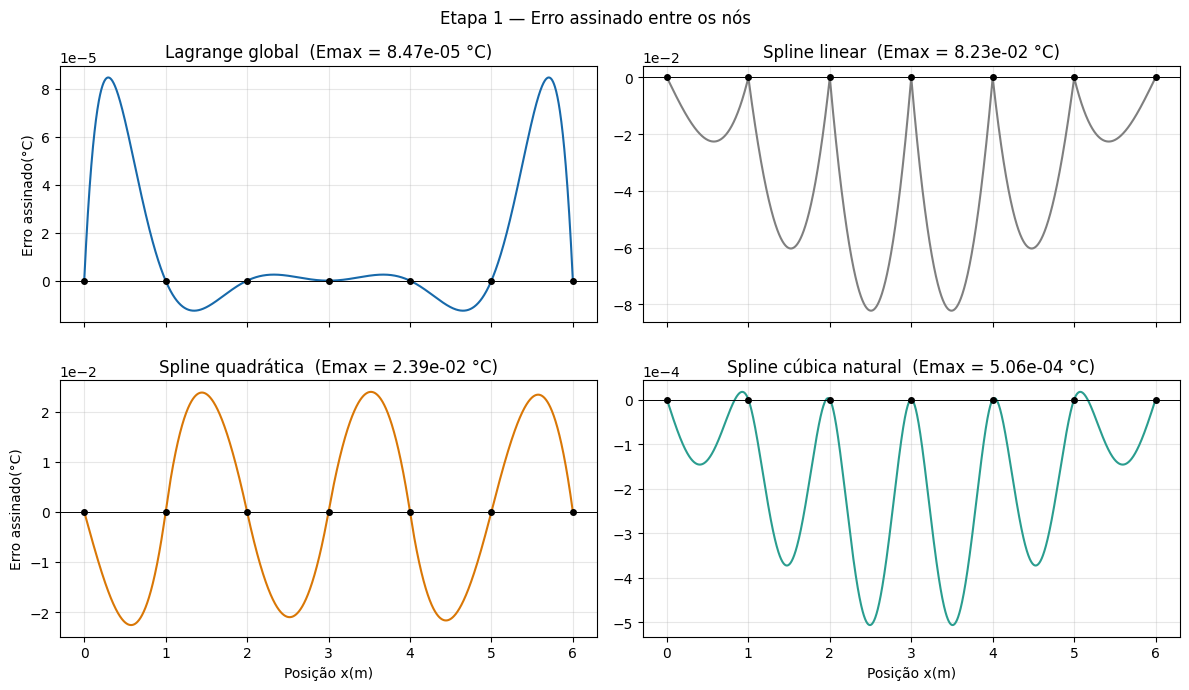

In [15]:
# Erros assinados (erro = metodo(x_fino) - T_fino)
fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharex=True)

for ax, (nome, metodo) in zip(axs.ravel(), metodos_7.items()):
    erro = metodo(x_fino) - T_fino
    ax.plot(x_fino, erro, color=cores[nome], lw=1.5)
    ax.plot(x_nos_7, np.zeros_like(x_nos_7), "ko", ms=4)
    ax.axhline(0, color="k", lw=0.7)
    ax.set_title(f"{nome}  (Emax = {np.max(np.abs(erro)):.2e} °C)")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
    ax.grid(alpha=0.3)

for ax in axs[1]: ax.set_xlabel("Posição x(m)")
for ax in axs[:, 0]: ax.set_ylabel("Erro assinado(°C)")

fig.suptitle("Etapa 1 — Erro assinado entre os nós")
plt.tight_layout(); plt.show()

## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

In [16]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

# Comparação equiespaçado x Chebyshev-Lobatto (somente Lagrange global)
linhas = []
for N in [5, 9, 13, 17]:
    for distrib, x_nos in [("Equiespaçado", np.linspace(x_min, x_max, N)),
                           ("Chebyshev", nos_chebyshev_lobatto(x_min, x_max, N))]:
        p = BarycentricInterpolator(x_nos, temperatura_real(x_nos))
        erro = p(x_fino) - T_fino
        linhas.append({"N": N, "Distribuição": distrib,
                       "Emax(°C)": np.max(np.abs(erro)),
                       "RMSE(°C)": np.sqrt(np.mean(erro**2))})
tabela_nos = pd.DataFrame(linhas)
display(tabela_nos.style.format({"Emax(°C)": "{:.3e}", "RMSE(°C)": "{:.3e}"}))

# Tabela pivotada para comparar lado a lado e razão entre os erros
pivo = tabela_nos.pivot(index="N", columns="Distribuição", values="Emax(°C)")
pivo["Razão Equi/Cheb"] = pivo["Equiespaçado"] / pivo["Chebyshev"]
display(pivo.style.format("{:.3e}"))

,N,Distribuição,Emax(°C),RMSE(°C)
0,5,Equiespaçado,4.530e-03,2.160e-03
1,5,Chebyshev,2.327e-03,1.533e-03
2,9,Equiespaçado,1.044e-06,3.438e-07
3,9,Chebyshev,2.168e-07,1.202e-07
4,13,Equiespaçado,5.917e-11,1.546e-11
5,13,Chebyshev,3.624e-12,1.932e-12
6,17,Equiespaçado,1.990e-12,2.445e-13
7,17,Chebyshev,1.421e-14,3.824e-15


Distribuição,Chebyshev,Equiespaçado,Razão Equi/Cheb
N,,,
5,2.327e-03,4.530e-03,1.947e+00
9,2.168e-07,1.044e-06,4.814e+00
13,3.624e-12,5.917e-11,1.633e+01
17,1.421e-14,1.990e-12,1.400e+02


In [17]:
# Comparação equiespaçado x Chebyshev-Lobatto (somente Lagrange global)
linhas = []
for N in [5, 9, 13, 17]:
    for distrib, x_nos in [("Equiespaçado", np.linspace(x_min, x_max, N)),
                           ("Chebyshev", nos_chebyshev_lobatto(x_min, x_max, N))]:
        p = BarycentricInterpolator(x_nos, temperatura_real(x_nos))
        erro = p(x_fino) - T_fino
        linhas.append({"N": N, "Distribuição": distrib,
                       "Emax (°C)": np.max(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
tabela_nos = pd.DataFrame(linhas)
display(tabela_nos.style.format({"Emax (°C)": "{:.3e}", "RMSE (°C)": "{:.3e}"}))

# Tabela pivotada para comparar lado a lado e razão entre os erros
pivo = tabela_nos.pivot(index="N", columns="Distribuição", values="Emax (°C)")
pivo["Razão Equi/Cheb"] = pivo["Equiespaçado"] / pivo["Chebyshev"]
display(pivo.style.format("{:.3e}"))

,N,Distribuição,Emax (°C),RMSE (°C)
0,5,Equiespaçado,4.530e-03,2.160e-03
1,5,Chebyshev,2.327e-03,1.533e-03
2,9,Equiespaçado,1.044e-06,3.438e-07
3,9,Chebyshev,2.168e-07,1.202e-07
4,13,Equiespaçado,5.912e-11,1.546e-11
5,13,Chebyshev,3.624e-12,1.932e-12
6,17,Equiespaçado,1.990e-12,2.445e-13
7,17,Chebyshev,1.421e-14,3.777e-15


Distribuição,Chebyshev,Equiespaçado,Razão Equi/Cheb
N,,,
5,2.327e-03,4.530e-03,1.947e+00
9,2.168e-07,1.044e-06,4.814e+00
13,3.624e-12,5.912e-11,1.631e+01
17,1.421e-14,1.990e-12,1.400e+02


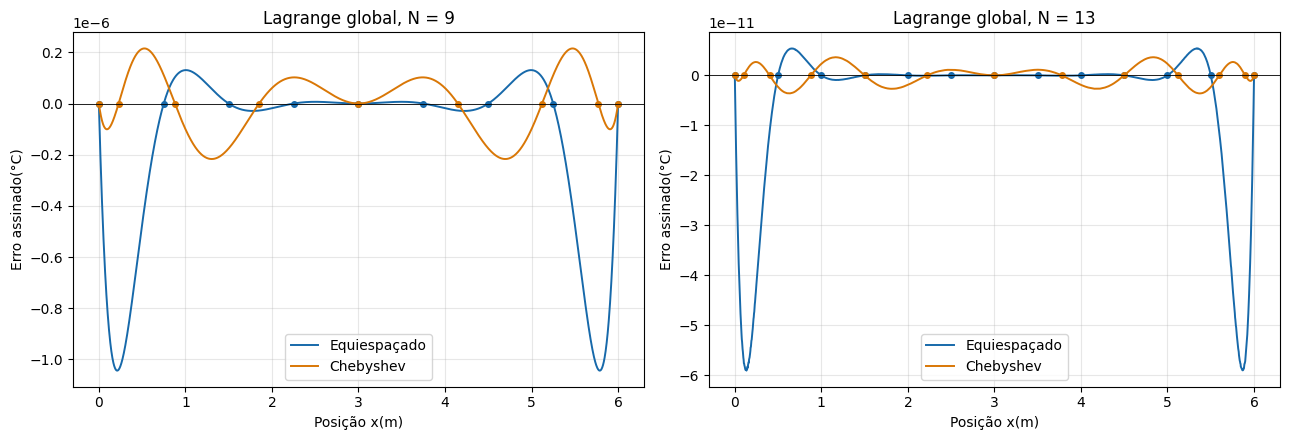

In [18]:
# Gráfico: onde o erro aparece ao longo da barra (N = 9 e N = 13)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, N in zip(axs, [9, 13]):
    for distrib, x_nos, cor in [("Equiespaçado", np.linspace(x_min, x_max, N), "#1769aa"),
                                ("Chebyshev", nos_chebyshev_lobatto(x_min, x_max, N), "#d97706")]:
        p = BarycentricInterpolator(x_nos, temperatura_real(x_nos))
        ax.plot(x_fino, p(x_fino) - T_fino, color=cor, lw=1.4, label=distrib)
        ax.plot(x_nos, np.zeros_like(x_nos), "o", color=cor, ms=4)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"Lagrange global, N = {N}")
    ax.set_xlabel("Posição x(m)"); ax.set_ylabel("Erro assinado(°C)")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

**Análise da Etapa 2 (aluno)**

- Para os dois tipos de nó, o erro cai muito rápido. É uma convergência espectral (exponencial), típica de função analítica.
- Para cada N, os nós de Chebyshev dão erro menor que os equiespaçados. A diferença cresce com N.
- Nos gráficos de erro, o caso equiespaçado tem o erro concentrado perto das extremidades, com oscilações maiores nos primeiros e últimos intervalos. No Chebyshev o erro é distribuído de forma mais uniforme. Isso acontece porque o polinômio nodal pi(x-x_i) tem amplitude bem menor nas bordas quando os nós são concentrados lá.

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

In [19]:
# Varredura N = 4 até N = 40, com erro e tempo de construção/avaliação
import time

def cronometrar(funcao, repeticoes=20):
    tempos = []
    for _ in range(repeticoes):
        t0 = time.perf_counter(); resultado = funcao(); tempos.append(time.perf_counter() - t0)
    return np.median(tempos), resultado

construtores = {
    "Lagrange equiespaçado": (lambda N: np.linspace(x_min, x_max, N),
                              lambda x, y: BarycentricInterpolator(x, y)),
    "Lagrange Chebyshev":    (lambda N: nos_chebyshev_lobatto(x_min, x_max, N),
                              lambda x, y: BarycentricInterpolator(x, y)),
    "Spline cúbica natural": (lambda N: np.linspace(x_min, x_max, N),
                              lambda x, y: CubicSpline(x, y, bc_type="natural")),
}

linhas = []
for N in range(4, 41):
    for nome, (gera_nos, constroi) in construtores.items():
        x_nos = gera_nos(N); y_nos = temperatura_real(x_nos)
        t_constr, p = cronometrar(lambda: constroi(x_nos, y_nos))
        t_aval, valores = cronometrar(lambda: p(x_fino))
        erro = valores - T_fino
        linhas.append({"N": N, "Método": nome,
                       "Emax(°C)": np.max(np.abs(erro)),
                       "RMSE(°C)": np.sqrt(np.mean(erro**2)),
                       "t_construção (µs)": 1e6*t_constr,
                       "t_avaliação (µs)": 1e6*t_aval})
estudo = pd.DataFrame(linhas)

# Resumo em alguns N
resumo = estudo[estudo["N"].isin([4, 7, 10, 15, 20, 25, 30, 40])]
display(resumo.pivot(index="N", columns="Método", values="Emax(°C)").style.format("{:.2e}"))

Método,Lagrange Chebyshev,Lagrange equiespaçado,Spline cúbica natural
N,,,
4,1.43e-01,1.09e-01,1.02e-02
7,3.35e-05,8.47e-05,5.06e-04
10,2.34e-07,7.52e-07,9.96e-05
15,2.49e-14,1.02e-12,1.66e-05
20,1.42e-14,1.04e-11,4.90e-06
25,1.42e-14,3.22e-10,1.92e-06
30,1.42e-14,1.40e-08,8.99e-07
40,1.78e-14,9.59e-06,2.75e-07


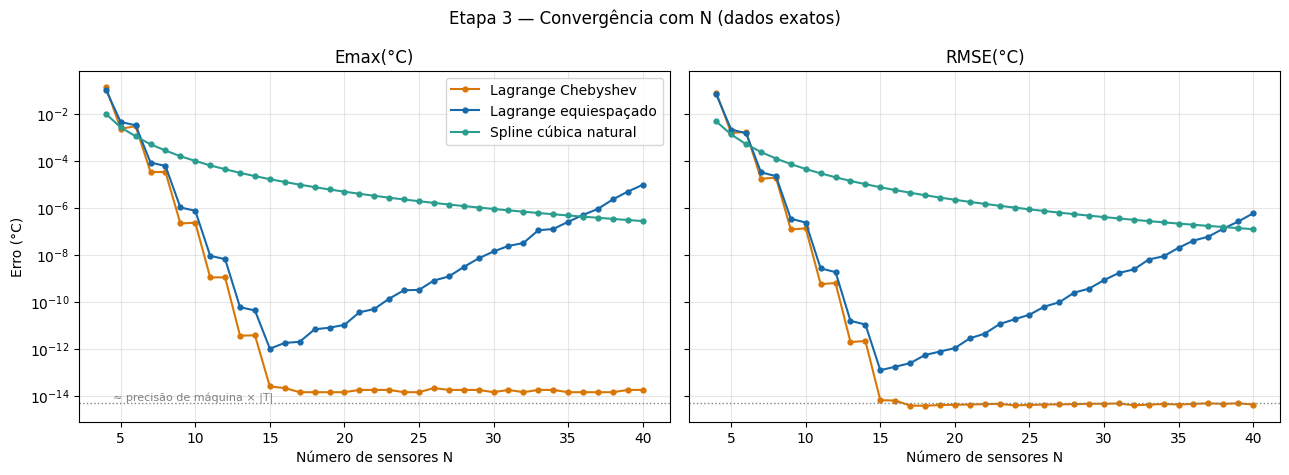

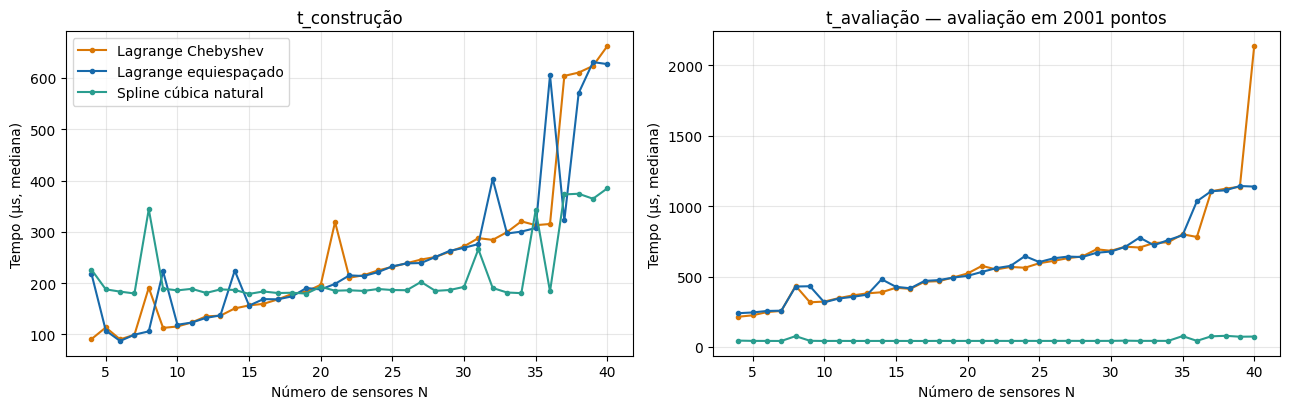

,N,Λ equiespaçado,Λ Chebyshev
0,7,4.55,2.08
1,13,89.3,2.54
2,25,1.38e+05,2.98
3,40,2.42e+09,3.29


In [20]:
# Gráficos de Emax, RMSE e tempos
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
cores3 = {"Lagrange equiespaçado": "#1769aa", "Lagrange Chebyshev": "#d97706",
          "Spline cúbica natural": "#2a9d8f"}

for ax, col in zip(axs, ["Emax(°C)", "RMSE(°C)"]):
    for nome, g in estudo.groupby("Método"):
        ax.semilogy(g["N"], g[col], "o-", ms=3.5, color=cores3[nome], label=nome)
    ax.axhline(np.finfo(float).eps * np.max(np.abs(T_fino)), color="gray", ls=":", lw=1)
    ax.set_xlabel("Número de sensores N"); ax.set_title(col)
    ax.grid(alpha=0.3, which="both")

axs[0].set_ylabel("Erro (°C)")
axs[0].text(4.5, 6e-15, "≈ precisão de máquina × |T|", color="gray", fontsize=8)
axs[0].legend()
fig.suptitle("Etapa 3 — Convergência com N (dados exatos)")
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))

for ax, col in zip(axs, ["t_construção (µs)", "t_avaliação (µs)"]):
    for nome, g in estudo.groupby("Método"):
        ax.plot(g["N"], g[col], "o-", ms=3, color=cores3[nome], label=nome)
    ax.set_xlabel("Número de sensores N"); ax.set_ylabel("Tempo (µs, mediana)")
    ax.set_title(col.replace(" (µs)", "") + f" — avaliação em {x_fino.size} pontos" if "aval" in col else col.replace(" (µs)", ""))
    ax.grid(alpha=0.3)
axs[0].legend()
plt.tight_layout(); plt.show()

# Constante de Lebesgue estimada: mede o quanto erros nos dados podem ser amplificados
def lebesgue(x_nos):
    soma = np.zeros_like(x_fino)

    for i in range(len(x_nos)):
        e = np.zeros(len(x_nos)); e[i] = 1.0
        soma += np.abs(BarycentricInterpolator(x_nos, e)(x_fino))

    return soma.max()

tab_leb = pd.DataFrame({"N": [7, 13, 25, 40],
    "Λ equiespaçado": [lebesgue(np.linspace(x_min, x_max, N)) for N in [7, 13, 25, 40]],
    "Λ Chebyshev":    [lebesgue(nos_chebyshev_lobatto(x_min, x_max, N)) for N in [7, 13, 25, 40]]})
display(tab_leb.style.format({"Λ equiespaçado": "{:.3g}", "Λ Chebyshev": "{:.3g}"}))

Precisão. Com dados exatos, o Lagrange com Chebyshev converge muito rápido e chega à precisão da máquina (erro da ordem de 1e-14 graus Celsius) por volta de N igual a 15. Depois disso o erro fica estável. O Lagrange com nós equiespaçados melhora até N entre 15 e 20, mas depois o erro volta a crescer e chega a algo entre 1e-6 e 1e-5 graus Celsius em N igual a 40, mesmo com dados exatos. Isso não é erro do método em si, e sim erro de arredondamento (da ordem de 1e-15) que vai sendo amplificado. Essa amplificação é medida pela constante de Lebesgue, que cresce de forma exponencial para nós equiespaçados e só de forma logarítmica para nós de Chebyshev. A spline cúbica natural converge de forma regular, mas mais devagar: no gráfico em escala log, a curva desce aos poucos. Com N igual a 40, ela ainda está na ordem de 1e-7 graus Celsius.

Custo. Todos os tempos medidos são da ordem de microssegundos, o que é irrelevante para uma barra com dezenas de sensores. Mesmo assim, há diferenças. No Lagrange baricêntrico, a construção (cálculo dos pesos) custa cerca de N ao quadrado operações e cada avaliação custa cerca de N, então avaliar m pontos custa cerca de m vezes N. Na spline cúbica, a construção resolve um sistema tridiagonal, que custa cerca de N operações. Cada avaliação custa cerca de log de N (para achar o intervalo certo) mais o cálculo de um polinômio de grau 3, então o tempo de avaliação é praticamente independente de N. Para N pequeno, a diferença de tempo é dominada pelo overhead do Python e do SciPy, então as medições oscilam e não devem ser interpretadas demais.

Existe um método superior para todo N? Não necessariamente. Neste perfil suave:

Para N muito pequeno, a spline ganha. Com N igual a 4, ela tem erro máximo da ordem de 1e-2 graus Celsius, contra cerca de 1e-1 dos dois Lagrange, porque um polinômio de grau 3 não consegue representar bem o perfil inteiro. Em N igual a 5, os três métodos ficam na mesma ordem de grandeza.

Para N intermediário, o Lagrange (equiespaçado ou Chebyshev) é muito melhor que a spline.

Para N grande, o Lagrange equiespaçado fica numericamente instável: piora a partir de N próximo de 15 e, de N próximo de 36 em diante, fica pior até do que a spline cúbica. A spline continua estável, só que menos precisa que o Lagrange com Chebyshev.

Ou seja, o melhor método depende de N, da posição dos nós e do critério usado (precisão com dados exatos ou robustez). Além disso, a vantagem do polinômio global depende de o perfil ser muito suave. Na prática, os sensores ficam onde é possível instalar, e quase nunca em posições de Chebyshev.

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

**Experimentos de apoio**

Para fundamentar a recomendação, simulei sensores com ruído gaussiano, ou seja, cada medição é a temperatura verdadeira mais um erro aleatório com média zero e desvio padrão sigma. Usei sigma igual a 0,05 e 0,10 graus Celsius, e números de sensores iguais a 7, 13 e 25. Para cada caso fiz 300 repetições (método de Monte Carlo) e calculei o erro máximo e o RMSE em relação ao perfil verdadeiro, e não em relação aos dados ruidosos. Além dos interpoladores, incluí um ajuste por mínimos quadrados com polinômio de grau 4, que não passa exatamente pelos pontos, para comparar interpolação com suavização.

In [21]:
# Monte Carlo com sensores ruidosos
rng = np.random.default_rng(2026)
n_realizacoes = 300

def metodos_ruido(x_eq, y_eq, x_ch, y_ch):
    return {
        "Lagrange equiespaçado": BarycentricInterpolator(x_eq, y_eq),
        "Lagrange Chebyshev":    BarycentricInterpolator(x_ch, y_ch),
        "Spline linear":         interp1d(x_eq, y_eq, kind="linear"),
        "Spline cúbica natural": CubicSpline(x_eq, y_eq, bc_type="natural"),
        "Mín. quadrados grau 4": np.polynomial.Polynomial.fit(x_eq, y_eq, 4),
    }

linhas = []

for sigma in [0.05, 0.10]:
    for N in [7, 13, 25]:
        x_eq = np.linspace(x_min, x_max, N); x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
        acumulado = {}
        for _ in range(n_realizacoes):
            y_eq = temperatura_real(x_eq) + rng.normal(0, sigma, N)
            y_ch = temperatura_real(x_ch) + rng.normal(0, sigma, N)
            for nome, p in metodos_ruido(x_eq, y_eq, x_ch, y_ch).items():
                erro = p(x_fino) - T_fino
                acumulado.setdefault(nome, []).append((np.max(np.abs(erro)), np.sqrt(np.mean(erro**2))))
        for nome, v in acumulado.items():
            v = np.array(v)
            linhas.append({"σ (°C)": sigma, "N": N, "Método": nome,
                           "Emax médio (°C)": v[:, 0].mean(), "RMSE médio (°C)": v[:, 1].mean()})
tabela_ruido = pd.DataFrame(linhas)

for sigma in [0.05, 0.10]:
    print(f"\nσ = {sigma} °C — RMSE médio (°C) em relação ao perfil verdadeiro")
    display(tabela_ruido[tabela_ruido["σ (°C)"] == sigma].pivot(index="Método", columns="N", values="RMSE médio (°C)").style.format("{:.3g}"))
    print(f"σ = {sigma} °C — Emax médio (°C)")
    display(tabela_ruido[tabela_ruido["σ (°C)"] == sigma].pivot(index="Método", columns="N", values="Emax médio (°C)").style.format("{:.3g}"))


σ = 0.05 °C — RMSE médio (°C) em relação ao perfil verdadeiro


N,7,13,25
Método,,,
Lagrange Chebyshev,0.046,0.0483,0.0495
Lagrange equiespaçado,0.059,0.377,343
Mín. quadrados grau 4,0.0377,0.0264,0.0202
Spline cúbica natural,0.0447,0.0454,0.0462
Spline linear,0.0591,0.0414,0.0407


σ = 0.05 °C — Emax médio (°C)


N,7,13,25
Método,,,
Lagrange Chebyshev,0.0913,0.108,0.125
Lagrange equiespaçado,0.128,1.59,2.14e+03
Mín. quadrados grau 4,0.0759,0.0574,0.0491
Spline cúbica natural,0.0905,0.103,0.117
Spline linear,0.114,0.1,0.113



σ = 0.1 °C — RMSE médio (°C) em relação ao perfil verdadeiro


N,7,13,25
Método,,,
Lagrange Chebyshev,0.0907,0.0945,0.0991
Lagrange equiespaçado,0.118,0.774,714
Mín. quadrados grau 4,0.0744,0.0543,0.0405
Spline cúbica natural,0.0884,0.09,0.0931
Spline linear,0.0903,0.0802,0.0816


σ = 0.1 °C — Emax médio (°C)


N,7,13,25
Método,,,
Lagrange Chebyshev,0.177,0.211,0.247
Lagrange equiespaçado,0.258,3.28,4.46e+03
Mín. quadrados grau 4,0.148,0.124,0.0986
Spline cúbica natural,0.178,0.208,0.235
Spline linear,0.186,0.201,0.226


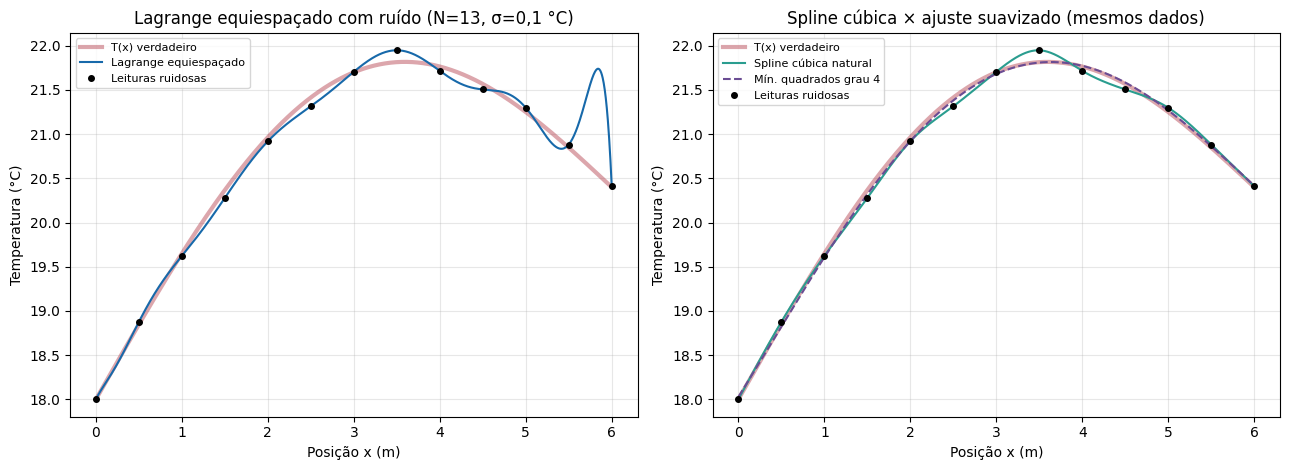

In [22]:
# Visualização de: N = 13, σ = 0.10 °C
rng_vis = np.random.default_rng(7)
N, sigma = 13, 0.10
x_eq = np.linspace(x_min, x_max, N); x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
y_eq = temperatura_real(x_eq) + rng_vis.normal(0, sigma, N)
y_ch = temperatura_real(x_ch) + rng_vis.normal(0, sigma, N)
ms = metodos_ruido(x_eq, y_eq, x_ch, y_ch)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
axs[0].plot(x_fino, T_fino, color="#b23a48", lw=3, alpha=0.45, label="T(x) verdadeiro")
axs[0].plot(x_fino, ms["Lagrange equiespaçado"](x_fino), color="#1769aa", label="Lagrange equiespaçado")
axs[0].plot(x_eq, y_eq, "ko", ms=4, label="Leituras ruidosas")
axs[0].set_title("Lagrange equiespaçado com ruído (N=13, σ=0,1 °C)")
axs[1].plot(x_fino, T_fino, color="#b23a48", lw=3, alpha=0.45, label="T(x) verdadeiro")
axs[1].plot(x_fino, ms["Spline cúbica natural"](x_fino), color="#2a9d8f", label="Spline cúbica natural")
axs[1].plot(x_fino, ms["Mín. quadrados grau 4"](x_fino), "--", color="#6a4c93", label="Mín. quadrados grau 4")
axs[1].plot(x_eq, y_eq, "ko", ms=4, label="Leituras ruidosas")
axs[1].set_title("Spline cúbica × ajuste suavizado (mesmos dados)")
for ax in axs:
    ax.set_xlabel("Posição x (m)"); ax.set_ylabel("Temperatura (°C)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

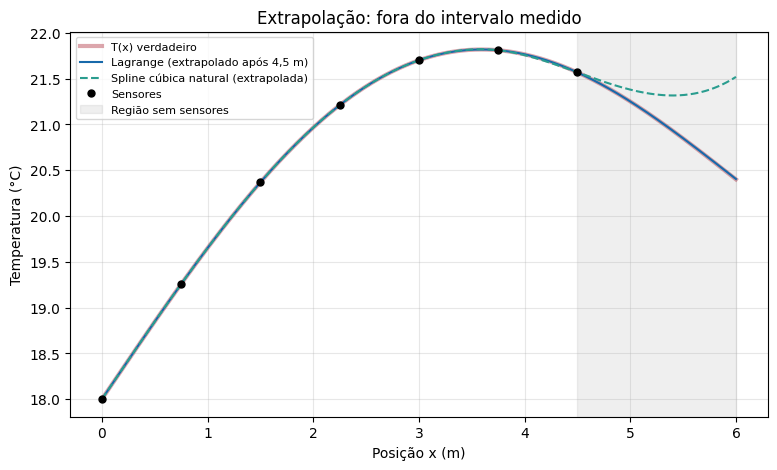

Lagrange: erro em x = 6 m = +0.0040 °C (com dados exatos; dentro de [0; 4,5] m o Emax é 3.3e-05 °C)
Spline cúbica natural: erro em x = 6 m = +1.1187 °C (com dados exatos; dentro de [0; 4,5] m o Emax é 1.4e-02 °C)


In [23]:
# Interpolação x extrapolação: sensores só em [0, 4.5] m, estimativa até 6 m
x_parcial = np.linspace(0, 4.5, 7)
y_parcial = temperatura_real(x_parcial)
x_ext = np.linspace(0, L, 601)
fig, ax = plt.subplots()
ax.plot(x_ext, temperatura_real(x_ext), color="#b23a48", lw=3, alpha=0.45, label="T(x) verdadeiro")
p_lag = BarycentricInterpolator(x_parcial, y_parcial)
p_cs = CubicSpline(x_parcial, y_parcial, bc_type="natural", extrapolate=True)
ax.plot(x_ext, p_lag(x_ext), color="#1769aa", label="Lagrange (extrapolado após 4,5 m)")
ax.plot(x_ext, p_cs(x_ext), color="#2a9d8f", ls="--", label="Spline cúbica natural (extrapolada)")
ax.plot(x_parcial, y_parcial, "ko", ms=5, label="Sensores")
ax.axvspan(4.5, L, color="gray", alpha=0.12, label="Região sem sensores")
ax.set_xlabel("Posição x (m)"); ax.set_ylabel("Temperatura (°C)")
ax.set_title("Extrapolação: fora do intervalo medido"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

for nome, p in [("Lagrange", p_lag), ("Spline cúbica natural", p_cs)]:
    print(f"{nome}: erro em x = 6 m = {float(p(L)) - temperatura_real(L):+.4f} °C "
          f"(com dados exatos; dentro de [0; 4,5] m o Emax é "
          f"{np.max(np.abs(p(x_ext[x_ext<=4.5]) - temperatura_real(x_ext[x_ext<=4.5]))):.1e} °C)")

Recomendação técnica

1. Poucos sensores exatos. Com cerca de 5 a 10 sensores confiáveis, eu usaria o polinômio de Lagrange (forma baricêntrica) ou a spline cúbica natural. Na Etapa 1, com 7 sensores, o Lagrange teve erro máximo de cerca de 8e-5 graus Celsius e a spline cúbica de cerca de 5e-4. A spline linear ficou em cerca de 8e-2. O Lagrange só vai tão bem porque o perfil é muito suave. A spline natural também é uma boa escolha, porque a segunda derivada é zero nas pontas.
2. Mais sensores. Com sensores equiespaçados, eu não aumentaria o grau do polinômio global: na Etapa 3, o erro dele volta a crescer depois de N igual a cerca de 16 e chega a cerca de 1e-5 com N igual a 40. Se os sensores puderem ser posicionados como em Chebyshev, o Lagrange continua estável. Caso contrário, eu passaria para a spline cúbica, que é estável e cujo erro continua caindo.
3. Sensores com ruído. Esse é o ponto mais importante. Com ruído, interpolar exatamente os dados reproduz o ruído. O Lagrange equiespaçado fica inaceitável, porque o erro explode quando N cresce. A spline cúbica fica estável, mas com erro da ordem do ruído, e esse erro não diminui com mais sensores. O ajuste por mínimos quadrados de grau baixo teve o menor erro e é o único que melhora com mais sensores, porque faz a média do ruído. Por isso, eu recomendaria um ajuste suavizado ou um modelo físico simples, escolhendo o grau por validação cruzada (deixar um sensor de fora e prever o valor dele) e informando a incerteza.
4. Extremidades. Colocar sensores exatamente nas duas pontas, onde a temperatura é conhecida, e, se possível, mais sensores perto delas. Evitar polinômio de grau alto com nós equiespaçados. A spline natural é coerente aqui, mas em outro problema a condição de contorno deve seguir a física.
5. Interpolação e extrapolação. Tudo acima vale dentro do intervalo coberto pelos sensores. Fora dele, nenhum método tem garantia. No seu teste, o Lagrange foi bem fora do intervalo só porque o perfil é muito suave e os dados eram exatos. Com ruído, ele amplifica tudo. Eu não extrapolaria sem um modelo físico ou um sensor adicional.
6. Limitações. Em campo, a temperatura verdadeira é desconhecida e não dá para calcular o erro como fizemos aqui. Restam a validação cruzada, a comparação entre métodos (se discordam muito, aquela região é incerta) e o conhecimento físico. Além disso, o modelo pode estar errado (perdas laterais, condutividade variando, regime não estacionário), e a interpolação não corrige isso.